MODULO 3 CAPITOLO 4 VIDEO 8 DBSCAN IN PYTHON 

In [1]:
import numpy as np 
import matplotlib.pyplot as plt 
from sklearn.datasets import make_moons
from sklearn.cluster import DBSCAN, KMeans


In [19]:
X, y = make_moons(n_samples=400, noise= 0.07, random_state=42)
print(f"X shape: {X.shape}\ny shape:{y.shape}")


X shape: (400, 2)
y shape:(400,)


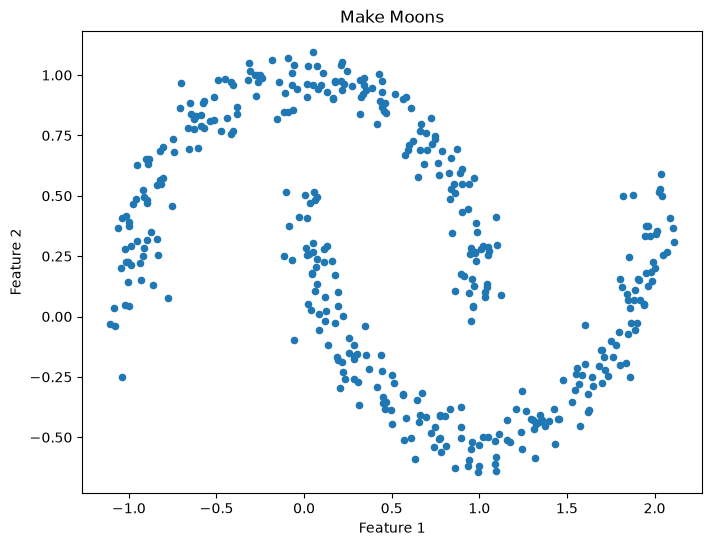

In [21]:
plt.figure(figsize=(8,6))
plt.scatter(X[:,0],X[:,1], s=20)
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Make Moons")
plt.show()


CREIAMO IL NOSTRO DBSCAN


In [24]:
#APPLICHIAMO IL NOSTRO DBSCAN HA BISOGNO DI DUE DATI EPSILON E MINSAMPLES(NUMERO PUNTI PER UNA ZONA AD ALTA DENSITA')

eps = 0.2
min_samples = 5
dbscan = DBSCAN(
    eps = eps,
    min_samples=min_samples
)
dbscan.fit(X)

labels = dbscan.labels_



In [26]:
n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
print(f"Found Clusters:\t{n_clusters}")


Found Clusters:	2


In [27]:
assigned = np.sum(labels != -1)
tot = len(labels)
noise = tot -assigned
print(f"Assigned: {assigned}\nNoise: {noise}\nPercentage of clustering: {assigned / tot * 100:.2f}%")


Assigned: 399
Noise: 1
Percentage of clustering: 99.75%


<>:14: SyntaxWarning: invalid escape sequence '\m'
<>:14: SyntaxWarning: invalid escape sequence '\m'
C:\Users\Utente\AppData\Local\Temp\ipykernel_6852\250242045.py:14: SyntaxWarning: invalid escape sequence '\m'
  plt.title("DBSCAN Clustering\n$eps = {eps}$\min_samples = {min_samples}")


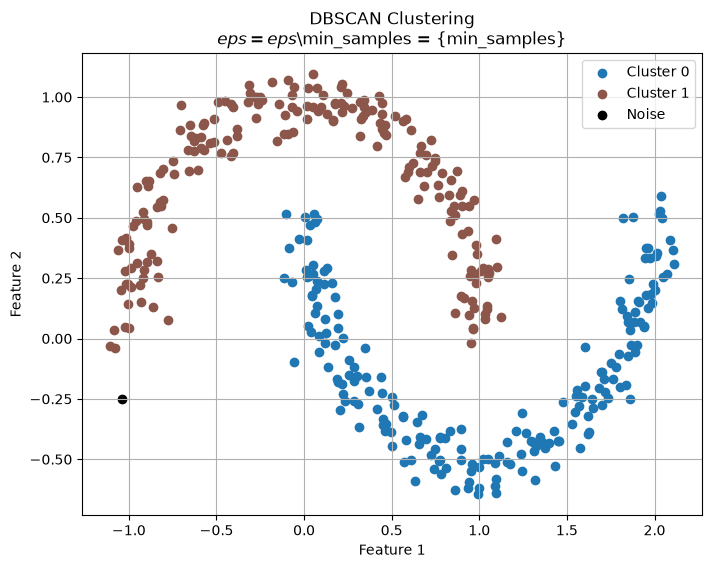

In [31]:
plt.figure(figsize=(8,6))
unique_labels = set(labels)
colors = [plt.cm.tab10(each) for each in np.linspace(0,1, len(unique_labels))]

for k, col in zip(unique_labels, colors):
    if k == -1:
        col = (0,0,0,1)
    class_member_mask = (labels == k)
    xy = X[class_member_mask]
    plt.scatter(xy[:,0], xy[:,1], c=[col], label=f"Cluster {k}" if k != -1 else "Noise")

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("DBSCAN Clustering\n$eps = {eps}$\min_samples = {min_samples}")
plt.legend()
plt.grid()
plt.show()


In [32]:
kmeans = KMeans(n_clusters=n_clusters, init = "k-means++", random_state=42)
clusters= kmeans.fit_predict(X)


c:\Users\Utente\AppData\Local\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


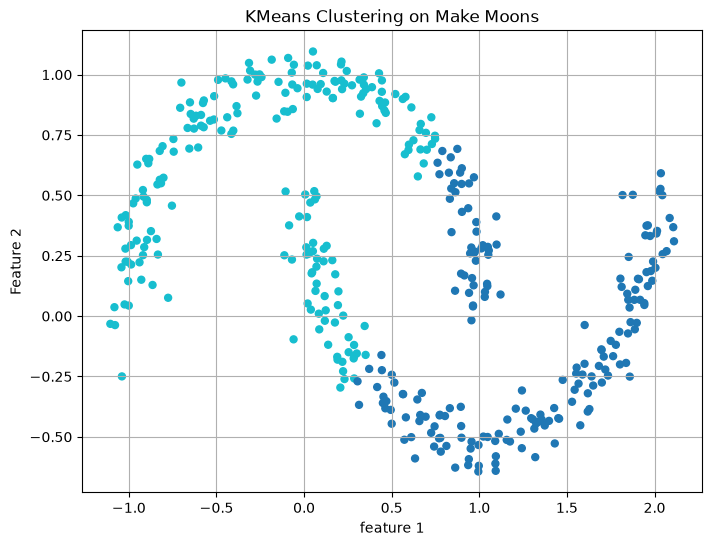

In [33]:
plt.figure(figsize=(8,6))
plt.title("KMeans Clustering on Make Moons")
plt.scatter(X[:,0], X[:,1], c=clusters, cmap="tab10", s=25)
plt.xlabel("feature 1")
plt.ylabel("Feature 2")
plt.grid()
plt.show()
